<a href="https://colab.research.google.com/github/Siddhesh-2028/RL_Assignment/blob/main/ML_RL_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

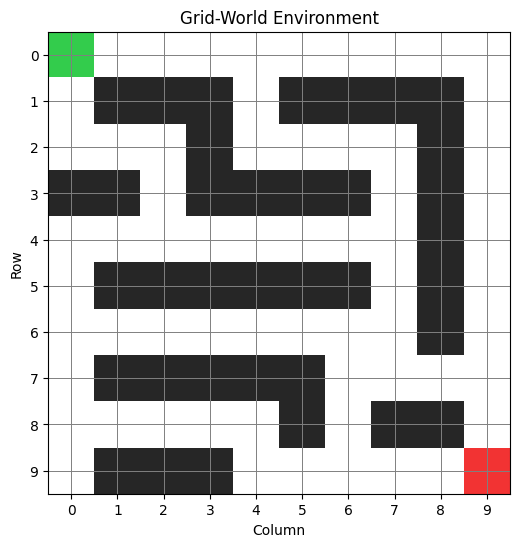

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Grid environment: 0 = free cell, 1 = obstacle
GRID = np.array([
    [0,0,0,0,0,0,0,0,0,0],
    [0,1,1,1,0,1,1,1,1,0],
    [0,0,0,1,0,0,0,0,1,0],
    [1,1,0,1,1,1,1,0,1,0],
    [0,0,0,0,0,0,0,0,1,0],
    [0,1,1,1,1,1,1,0,1,0],
    [0,0,0,0,0,0,0,0,1,0],
    [0,1,1,1,1,1,0,0,0,0],
    [0,0,0,0,0,1,0,1,1,0],
    [0,1,1,1,0,0,0,0,0,0]
])

# Starting and goal positions (row, column)
START = (0, 0)
GOAL = (9, 9)

# Display the grid environment
def display_grid():
    image = np.ones((*GRID.shape, 3))

    # Free cells: white
    image[GRID == 0] = [1, 1, 1]

    # Obstacles: black
    image[GRID == 1] = [0.15, 0.15, 0.15]

    # Start: green
    image[START] = [0.2, 0.8, 0.3]

    # Goal: red
    image[GOAL] = [0.95, 0.2, 0.2]

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.xticks(range(GRID.shape[1]))
    plt.yticks(range(GRID.shape[0]))
    plt.grid(True, color="gray", linewidth=0.7)
    plt.title("Grid-World Environment")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.show()

display_grid()

In [ ]:

from time import perf_counter

def get_neighbors(position):
    row, col = position

    # Movement order: Down, Right, Up, Left
    directions = [(1, 0), (0, 1), (-1, 0), (0, -1)]

    neighbors = []

    for dr, dc in directions:
        nr, nc = row + dr, col + dc

        # Check grid boundaries and obstacles
        if (0 <= nr < GRID.shape[0] and
            0 <= nc < GRID.shape[1] and
            GRID[nr, nc] == 0):
            neighbors.append((nr, nc))

    return neighbors


def dfs():
    stack = [START]
    visited = set()
    parent = {START: None}
    explored_order = []

    while stack:
        current = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        explored_order.append(current)

        # Stop when the goal is reached
        if current == GOAL:
            break

        for neighbor in get_neighbors(current):
            if neighbor not in visited and neighbor not in parent:
                parent[neighbor] = current
                stack.append(neighbor)

    # Reconstruct the path from start to goal
    path = []

    if GOAL in visited:
        current = GOAL

        while current is not None:
            path.append(current)
            current = parent[current]

        path.reverse()

    return path, explored_order


# Run DFS and measure execution time
start_time = perf_counter()
dfs_path, dfs_explored = dfs()
dfs_time = perf_counter() - start_time

print("DFS Results")
print("Path:", dfs_path)
print("Path length:", len(dfs_path) - 1 if dfs_path else "No path found")
print("Cells explored:", len(dfs_explored))
print(f"Execution time: {dfs_time * 1000:.3f} ms")

DFS Results
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (7, 8), (7, 7), (7, 6), (6, 6), (6, 5), (6, 4), (6, 3), (6, 2), (6, 1), (6, 0), (7, 0), (8, 0), (8, 1), (8, 2), (8, 3), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
Path length: 38
Cells explored: 58
Execution time: 0.306 ms


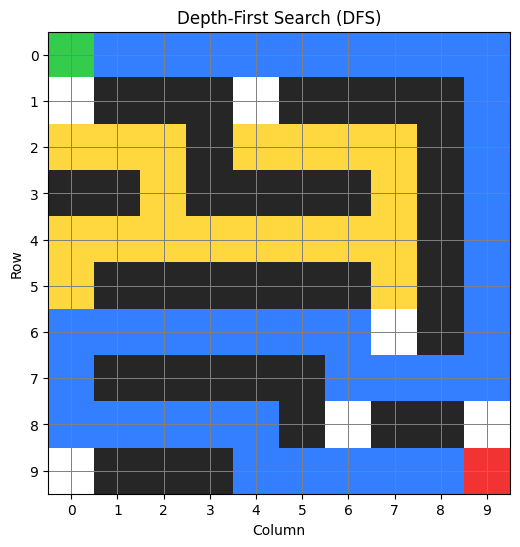

In [ ]:

def visualize_dfs():
    image = np.ones((*GRID.shape, 3))

    # Obstacles
    image[GRID == 1] = [0.15, 0.15, 0.15]

    # Explored cells: yellow
    for row, col in dfs_explored:
        image[row, col] = [1.0, 0.85, 0.25]

    # Final path: blue
    for row, col in dfs_path:
        image[row, col] = [0.2, 0.5, 1.0]

    # Start and goal
    image[START] = [0.2, 0.8, 0.3]
    image[GOAL] = [0.95, 0.2, 0.2]

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.xticks(range(GRID.shape[1]))
    plt.yticks(range(GRID.shape[0]))
    plt.grid(True, color="gray", linewidth=0.7)
    plt.title("Depth-First Search (DFS)")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.show()


visualize_dfs()

In [ ]:

from collections import deque
from time import perf_counter

def bfs():
    queue = deque([START])
    visited = {START}
    parent = {START: None}
    explored_order = []

    while queue:
        current = queue.popleft()
        explored_order.append(current)

        # Stop when the goal is reached
        if current == GOAL:
            break

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    # Reconstruct the path
    path = []

    if GOAL in visited:
        current = GOAL

        while current is not None:
            path.append(current)
            current = parent[current]

        path.reverse()

    return path, explored_order


# Run BFS and measure execution time
start_time = perf_counter()
bfs_path, bfs_explored = bfs()
bfs_time = perf_counter() - start_time

print("BFS Results")
print("Path:", bfs_path)
print("Path length:", len(bfs_path) - 1 if bfs_path else "No path found")
print("Cells explored:", len(bfs_explored))
print(f"Execution time: {bfs_time * 1000:.3f} ms")

BFS Results
Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7), (7, 7), (7, 8), (7, 9), (8, 9), (9, 9)]
Path length: 18
Cells explored: 61
Execution time: 0.291 ms


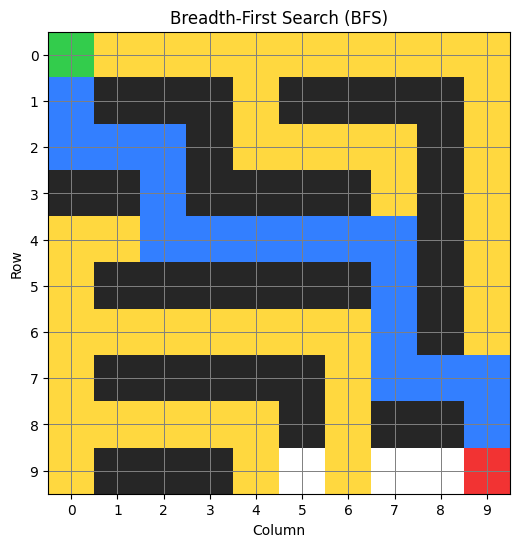

In [ ]:

def visualize_bfs():
    image = np.ones((*GRID.shape, 3))

    # Obstacles: black
    image[GRID == 1] = [0.15, 0.15, 0.15]

    # Explored cells: yellow
    for row, col in bfs_explored:
        image[row, col] = [1.0, 0.85, 0.25]

    # Final shortest path: blue
    for row, col in bfs_path:
        image[row, col] = [0.2, 0.5, 1.0]

    # Start: green; Goal: red
    image[START] = [0.2, 0.8, 0.3]
    image[GOAL] = [0.95, 0.2, 0.2]

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.xticks(range(GRID.shape[1]))
    plt.yticks(range(GRID.shape[0]))
    plt.grid(True, color="gray", linewidth=0.7)
    plt.title("Breadth-First Search (BFS)")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.show()

visualize_bfs()

In [ ]:

import heapq
from time import perf_counter

def astar():
    # Manhattan distance heuristic
    def heuristic(position):
        row, col = position
        goal_row, goal_col = GOAL
        return abs(row - goal_row) + abs(col - goal_col)

    # Priority queue: (f_cost, tie_breaker, position)
    counter = 0
    priority_queue = [(heuristic(START), counter, START)]

    parent = {START: None}
    g_cost = {START: 0}
    explored_order = []
    explored_set = set()

    while priority_queue:
        _, _, current = heapq.heappop(priority_queue)

        # Ignore outdated entries
        if current in explored_set:
            continue

        explored_set.add(current)
        explored_order.append(current)

        # Stop when the goal is reached
        if current == GOAL:
            break

        for neighbor in get_neighbors(current):
            new_cost = g_cost[current] + 1

            if new_cost < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = new_cost
                parent[neighbor] = current

                counter += 1
                f_cost = new_cost + heuristic(neighbor)

                heapq.heappush(
                    priority_queue,
                    (f_cost, counter, neighbor)
                )

    # Reconstruct the path
    path = []

    if GOAL in parent:
        current = GOAL

        while current is not None:
            path.append(current)
            current = parent[current]

        path.reverse()

    return path, explored_order


# Run A* and measure execution time
start_time = perf_counter()
astar_path, astar_explored = astar()
astar_time = perf_counter() - start_time

print("A* Search Results")
print("Path:", astar_path)
print(
    "Path length:",
    len(astar_path) - 1 if astar_path else "No path found"
)
print("Cells explored:", len(astar_explored))
print(f"Execution time: {astar_time * 1000:.3f} ms")

A* Search Results
Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7), (7, 7), (7, 8), (7, 9), (8, 9), (9, 9)]
Path length: 18
Cells explored: 40
Execution time: 0.352 ms


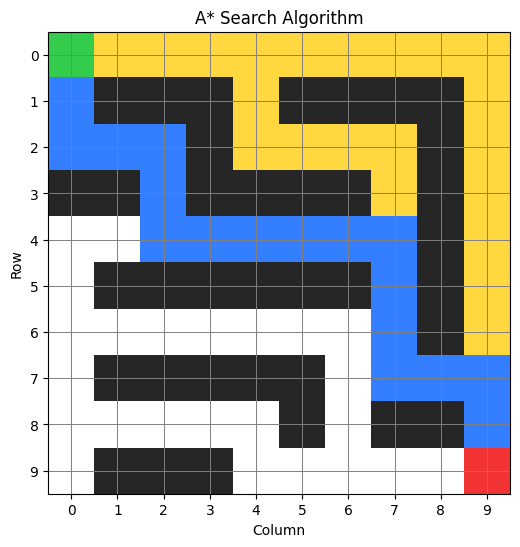

In [ ]:

def visualize_astar():
    image = np.ones((*GRID.shape, 3))

    # Obstacles: black
    image[GRID == 1] = [0.15, 0.15, 0.15]

    # Explored cells: yellow
    for row, col in astar_explored:
        image[row, col] = [1.0, 0.85, 0.25]

    # Final path: blue
    for row, col in astar_path:
        image[row, col] = [0.2, 0.5, 1.0]

    # Start: green; Goal: red
    image[START] = [0.2, 0.8, 0.3]
    image[GOAL] = [0.95, 0.2, 0.2]

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.xticks(range(GRID.shape[1]))
    plt.yticks(range(GRID.shape[0]))
    plt.grid(True, color="gray", linewidth=0.7)
    plt.title("A* Search Algorithm")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.show()

visualize_astar()

In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Algorithm": ["DFS", "BFS", "A*"],
    "Path Length (steps)": [
        len(dfs_path) - 1 if dfs_path else None,
        len(bfs_path) - 1 if bfs_path else None,
        len(astar_path) - 1 if astar_path else None
    ],
    "Cells Explored": [
        len(dfs_explored),
        len(bfs_explored),
        len(astar_explored)
    ],
    "Execution Time (ms)": [
        dfs_time * 1000,
        bfs_time * 1000,
        astar_time * 1000
    ]
})

display(comparison.round(3))

,Algorithm,Path Length (steps),Cells Explored,Execution Time (ms)
0,DFS,38,58,0.306
1,BFS,18,61,0.291
2,A*,18,40,0.352


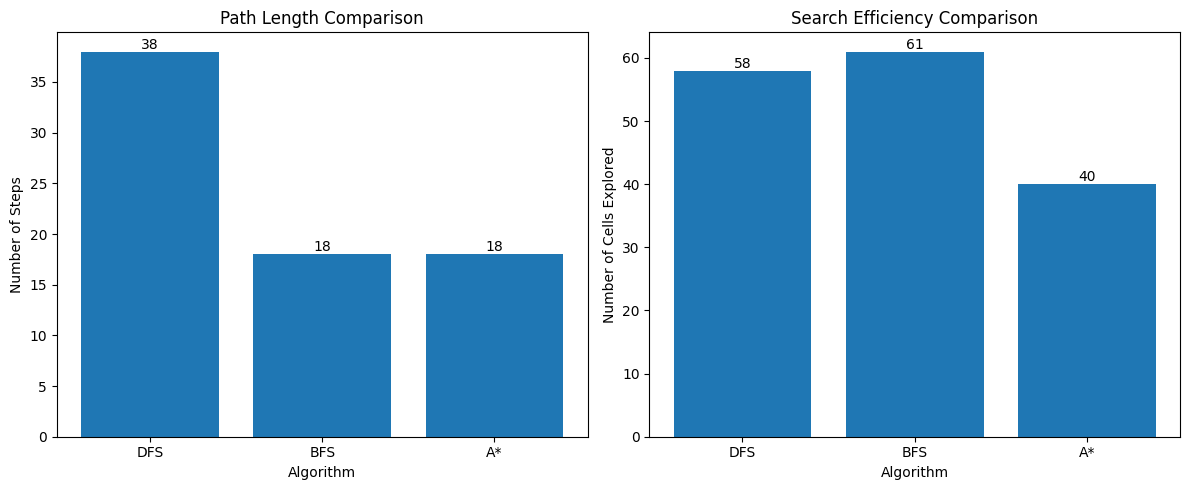

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

algorithms = ["DFS", "BFS", "A*"]

path_lengths = [
    len(dfs_path) - 1 if dfs_path else 0,
    len(bfs_path) - 1 if bfs_path else 0,
    len(astar_path) - 1 if astar_path else 0
]

explored_cells = [
    len(dfs_explored),
    len(bfs_explored),
    len(astar_explored)
]

# Create side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(algorithms, path_lengths)
axes[0].set_title("Path Length Comparison")
axes[0].set_ylabel("Number of Steps")
axes[0].set_xlabel("Algorithm")

for i, value in enumerate(path_lengths):
    axes[0].text(i, value, str(value), ha="center", va="bottom")

axes[1].bar(algorithms, explored_cells)
axes[1].set_title("Search Efficiency Comparison")
axes[1].set_ylabel("Number of Cells Explored")
axes[1].set_xlabel("Algorithm")

for i, value in enumerate(explored_cells):
    axes[1].text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

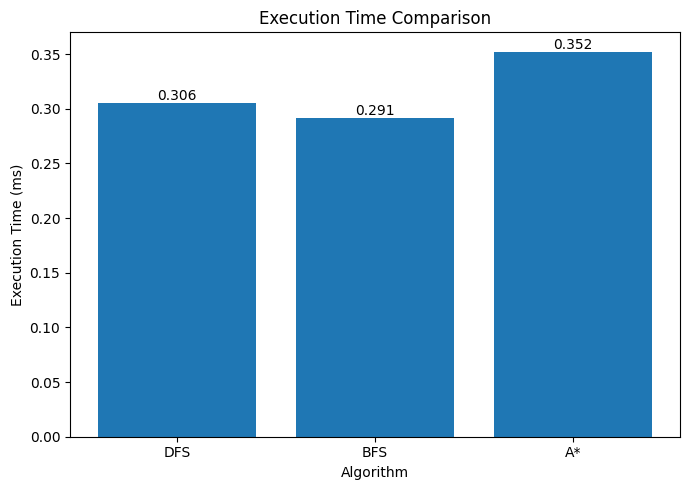

In [ ]:

execution_times = [
    dfs_time * 1000,
    bfs_time * 1000,
    astar_time * 1000
]

plt.figure(figsize=(7, 5))
plt.bar(algorithms, execution_times)
plt.title("Execution Time Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Execution Time (ms)")

for i, value in enumerate(execution_times):
    plt.text(i, value, f"{value:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import random
import matplotlib.pyplot as plt
import time

# Actions: Up, Down, Left, Right
ACTIONS = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, -1),
    3: (0, 1)
}

def reset_environment():
    return START

def take_action(state, action):
    row, col = state
    dr, dc = ACTIONS[action]
    nr, nc = row + dr, col + dc

    # Wall or obstacle collision
    if (nr < 0 or nr >= GRID.shape[0] or
        nc < 0 or nc >= GRID.shape[1] or
        GRID[nr, nc] == 1):
        return state, -5, False

    next_state = (nr, nc)

    # Goal reached
    if next_state == GOAL:
        return next_state, 100, True

    # Normal movement
    return next_state, -1, False

In [ ]:

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Hyperparameters
LEARNING_RATE = 0.1
DISCOUNT_FACTOR = 0.95
EPSILON = 1.0
EPSILON_DECAY = 0.995
MIN_EPSILON = 0.05

EPISODES = 500
MAX_STEPS = 200

# Q-table: rows x columns x 4 actions
Q = np.zeros((*GRID.shape, len(ACTIONS)))

episode_rewards = []
episode_steps = []
episode_success = []

start_time = time.perf_counter()

for episode in range(EPISODES):
    state = reset_environment()
    total_reward = 0
    reached_goal = False

    for step in range(MAX_STEPS):
        # Epsilon-greedy action selection
        if random.random() < EPSILON:
            action = random.choice(list(ACTIONS.keys()))
        else:
            action = int(np.argmax(Q[state]))

        next_state, reward, done = take_action(state, action)

        # Q-learning update
        old_value = Q[state][action]
        next_max = np.max(Q[next_state])

        Q[state][action] = old_value + LEARNING_RATE * (
            reward + DISCOUNT_FACTOR * next_max - old_value
        )

        state = next_state
        total_reward += reward

        if done:
            reached_goal = True
            break

    episode_rewards.append(total_reward)
    episode_steps.append(step + 1)
    episode_success.append(int(reached_goal))

    # Reduce exploration gradually
    EPSILON = max(MIN_EPSILON, EPSILON * EPSILON_DECAY)

training_time = time.perf_counter() - start_time

print("Q-Learning Training Complete")
print(f"Episodes: {EPISODES}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Final epsilon: {EPSILON:.3f}")
print(f"Success rate (last 100 episodes): "
      f"{np.mean(episode_success[-100:]) * 100:.1f}%")

Q-Learning Training Complete
Episodes: 500
Training time: 0.69 seconds
Final epsilon: 0.082
Success rate (last 100 episodes): 100.0%


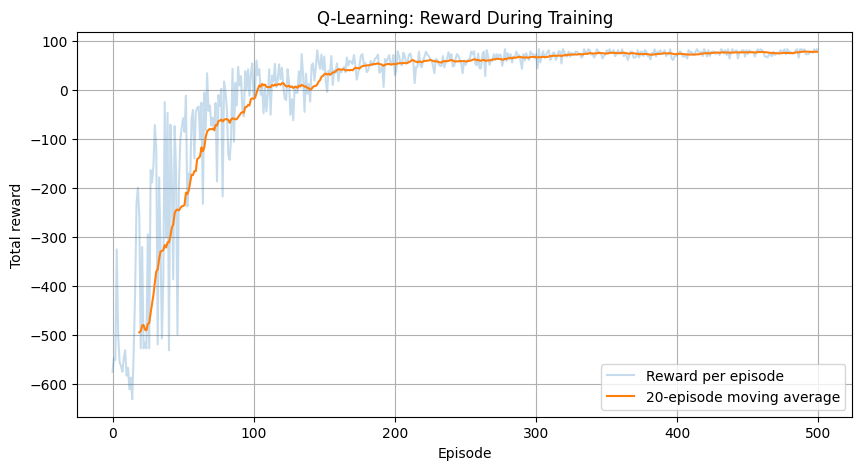

In [ ]:

def moving_average(values, window=20):
    return np.convolve(
        values, np.ones(window) / window, mode="valid"
    )

plt.figure(figsize=(10, 5))

plt.plot(episode_rewards, alpha=0.25, label="Reward per episode")
plt.plot(
    range(19, len(episode_rewards)),
    moving_average(episode_rewards, 20),
    label="20-episode moving average"
)

plt.title("Q-Learning: Reward During Training")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.legend()
plt.grid(True)
plt.show()

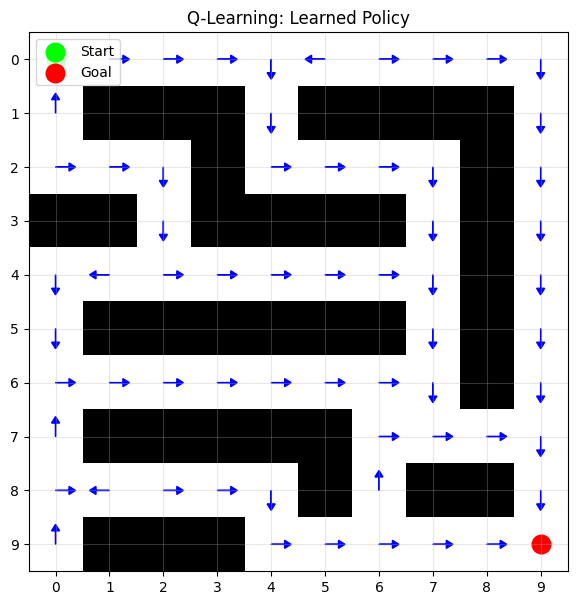

In [ ]:

def visualize_q_policy():
    arrows = {
        0: (0, -0.25),   # Up
        1: (0, 0.25),    # Down
        2: (-0.25, 0),   # Left
        3: (0.25, 0)     # Right
    }

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(GRID, cmap="Greys", origin="upper", vmin=0, vmax=1)

    for row in range(GRID.shape[0]):
        for col in range(GRID.shape[1]):
            if GRID[row, col] == 1:
                continue

            if (row, col) in [START, GOAL]:
                continue

            # Draw an arrow only if the agent has learned
            # a nonzero value for at least one action
            if np.max(np.abs(Q[row, col])) > 0:
                action = int(np.argmax(Q[row, col]))
                dx, dy = arrows[action]

                ax.arrow(
                    col, row, dx, dy,
                    head_width=0.15,
                    head_length=0.12,
                    fc="blue", ec="blue"
                )

    ax.scatter(START[1], START[0], c="lime", s=180, label="Start")
    ax.scatter(GOAL[1], GOAL[0], c="red", s=180, label="Goal")

    ax.set_xticks(range(GRID.shape[1]))
    ax.set_yticks(range(GRID.shape[0]))
    ax.grid(True, alpha=0.3)
    ax.set_title("Q-Learning: Learned Policy")
    ax.legend()
    plt.show()

visualize_q_policy()

In [ ]:

def test_q_agent():
    state = START
    path = [state]
    total_reward = 0

    for _ in range(MAX_STEPS):
        action = int(np.argmax(Q[state]))
        next_state, reward, done = take_action(state, action)

        total_reward += reward

        # Prevent an infinite loop in the greedy policy
        if not done and next_state == state:
            available = [
                a for a in ACTIONS
                if take_action(state, a)[0] != state
            ]

            if not available:
                break

            action = max(available, key=lambda a: Q[state][a])
            next_state, reward, done = take_action(state, action)
            total_reward += reward

        if next_state == state:
            break

        state = next_state
        path.append(state)

        if done:
            break

    return path, total_reward, state == GOAL


test_path, test_reward, test_success = test_q_agent()

print("Greedy Test Results")
print("Reached goal:", test_success)
print("Path:", test_path)
print("Path length:", len(test_path) - 1)
print("Total reward:", test_reward)

Greedy Test Results
Reached goal: True
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (2, 6), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7), (7, 8), (7, 9), (8, 9), (9, 9)]
Path length: 18
Total reward: 83


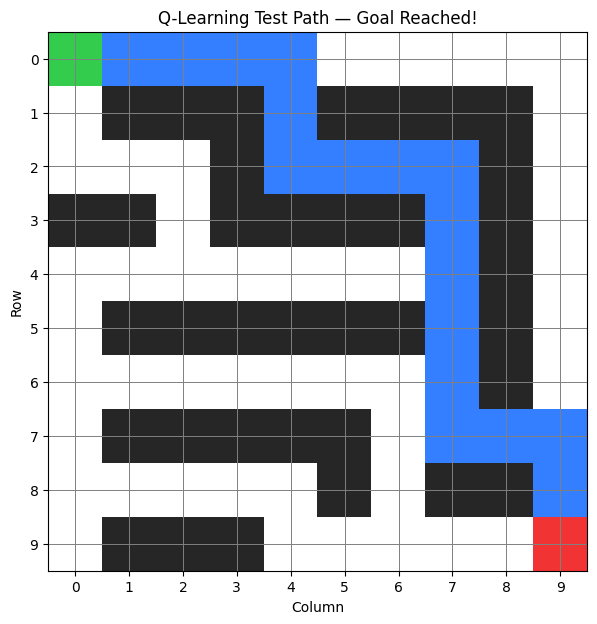

In [ ]:

def visualize_q_test_path():
    image = np.ones((*GRID.shape, 3))

    # Free cells: white
    image[GRID == 0] = [1, 1, 1]

    # Obstacles: black
    image[GRID == 1] = [0.15, 0.15, 0.15]

    # Path taken by the trained agent: blue
    for row, col in test_path:
        image[row, col] = [0.2, 0.5, 1.0]

    # Start: green
    image[START] = [0.2, 0.8, 0.3]

    # Goal: red
    image[GOAL] = [0.95, 0.2, 0.2]

    plt.figure(figsize=(7, 7))
    plt.imshow(image)

    plt.xticks(range(GRID.shape[1]))
    plt.yticks(range(GRID.shape[0]))
    plt.grid(True, color="gray", linewidth=0.7)

    status = "Goal Reached!" if test_success else "Goal Not Reached"
    plt.title(f"Q-Learning Test Path — {status}")
    plt.xlabel("Column")
    plt.ylabel("Row")

    plt.show()

visualize_q_test_path()

In [ ]:
!pip install -q stable-baselines3 gymnasium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 3.7 MB/s eta 0:00:00


In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import time
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

class GridWorldEnv(gym.Env):
    def __init__(self):
        super().__init__()

        self.rows, self.cols = GRID.shape
        self.action_space = spaces.Discrete(4)

        # Observation = current cell encoded as a number
        self.observation_space = spaces.Discrete(
            self.rows * self.cols
        )

        self.max_steps = 200
        self.steps = 0
        self.state = START

    def encode(self, state):
        return state[0] * self.cols + state[1]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.state = START
        self.steps = 0
        return self.encode(self.state), {}

    def step(self, action):
        self.steps += 1

        row, col = self.state
        directions = {
            0: (-1, 0),  # Up
            1: (1, 0),   # Down
            2: (0, -1),  # Left
            3: (0, 1)    # Right
        }

        dr, dc = directions[int(action)]
        nr, nc = row + dr, col + dc

        # Penalize walls and out-of-bounds moves
        if (nr < 0 or nr >= self.rows or
            nc < 0 or nc >= self.cols or
            GRID[nr, nc] == 1):

            reward = -5
        else:
            self.state = (nr, nc)
            reward = -1

        terminated = self.state == GOAL

        if terminated:
            reward = 100

        truncated = (
            self.steps >= self.max_steps and not terminated
        )

        return (
            self.encode(self.state),
            reward,
            terminated,
            truncated,
            {}
        )

env = GridWorldEnv()
print("PPO environment created successfully!")

PPO environment created successfully!


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
SEED = 42
TOTAL_TIMESTEPS = 30000

model = PPO(
    "MlpPolicy",
    env,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    gamma=0.95,
    verbose=1,
    seed=SEED
)

start_time = time.perf_counter()
model.learn(total_timesteps=TOTAL_TIMESTEPS)
ppo_training_time = time.perf_counter() - start_time

print("\nPPO Training Complete")
print(f"Timesteps: {TOTAL_TIMESTEPS}")
print(f"Training time: {ppo_training_time:.2f} seconds")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 174      |
|    ep_rew_mean     | -469     |
| time/              |          |
|    fps             | 1094     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 1024     |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 187          |
|    ep_rew_mean          | -524         |
| time/                   |              |
|    fps                  | 827          |
|    iterations           | 2            |
|    time_elapsed         | 2            |
|    total_timesteps      | 2048         |
| train/                  |              |
|    approx_kl            | 0.0010562068 |
|    clip_fraction        | 0            |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.39        |
|    explained_variance   | -0.0015      |
|    learning_rate        | 0.0003       |
|    loss                 | 366          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.00682     |
|    value_loss           | 782          |
------------------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len

PPO Test Results
Reached goal: False
Path length: 200
Total reward: -200
Path: [(0, 0), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), (0, 1), (0, 2), 

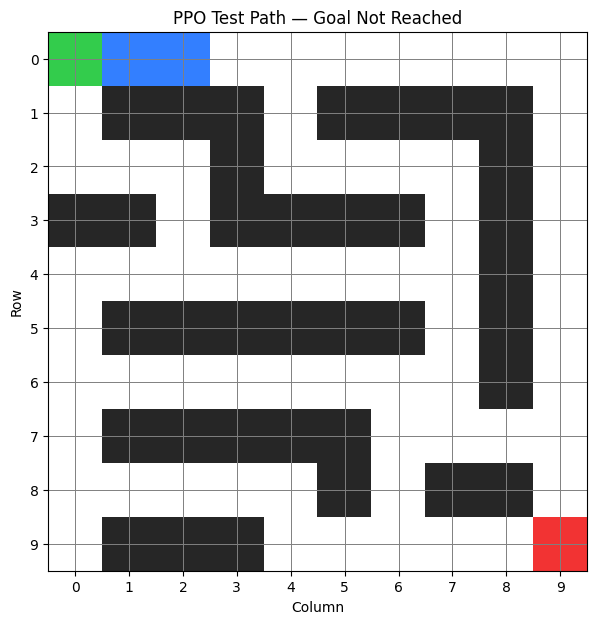

In [ ]:
obs, _ = env.reset(seed=SEED)
ppo_path = [START]
ppo_total_reward = 0
ppo_success = False

for _ in range(env.max_steps):
    action, _ = model.predict(obs, deterministic=True)

    obs, reward, terminated, truncated, _ = env.step(
        int(action)
    )

    ppo_total_reward += reward
    state = (
        obs // env.cols,
        obs % env.cols
    )

    if state != ppo_path[-1]:
        ppo_path.append(state)

    if terminated:
        ppo_success = True
        break

    if truncated:
        break

print("PPO Test Results")
print("Reached goal:", ppo_success)
print("Path length:", len(ppo_path) - 1)
print("Total reward:", ppo_total_reward)
print("Path:", ppo_path)

# Visualize the path
image = np.ones((*GRID.shape, 3))
image[GRID == 1] = [0.15, 0.15, 0.15]

for r, c in ppo_path:
    image[r, c] = [0.2, 0.5, 1.0]

image[START] = [0.2, 0.8, 0.3]
image[GOAL] = [0.95, 0.2, 0.2]

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.xticks(range(GRID.shape[1]))
plt.yticks(range(GRID.shape[0]))
plt.grid(True, color="gray", linewidth=0.7)
plt.title(f"PPO Test Path — {'Goal Reached!' if ppo_success else 'Goal Not Reached'}")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()

In [ ]:
class GridWorldEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.rows, self.cols = GRID.shape
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Discrete(
            self.rows * self.cols
        )
        self.max_steps = 200
        self.steps = 0
        self.state = START

    def encode(self, state):
        return state[0] * self.cols + state[1]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.state = START
        self.steps = 0
        return self.encode(self.state), {}

    def step(self, action):
        self.steps += 1
        row, col = self.state

        directions = {
            0: (-1, 0), 1: (1, 0),
            2: (0, -1), 3: (0, 1)
        }

        old_distance = abs(row - GOAL[0]) + abs(col - GOAL[1])
        dr, dc = directions[int(action)]
        nr, nc = row + dr, col + dc

        if (nr < 0 or nr >= self.rows or
            nc < 0 or nc >= self.cols or
            GRID[nr, nc] == 1):
            reward = -5
        else:
            self.state = (nr, nc)
            new_distance = abs(nr - GOAL[0]) + abs(nc - GOAL[1])

            # Small guidance reward for reducing Manhattan distance
            reward = -1 + 0.5 * (old_distance - new_distance)

        terminated = self.state == GOAL

        if terminated:
            reward = 100

        truncated = self.steps >= self.max_steps and not terminated

        return (
            self.encode(self.state),
            reward,
            terminated,
            truncated,
            {}
        )

In [ ]:
env = GridWorldEnv()

model = PPO(
    "MlpPolicy",
    env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    gamma=0.99,
    ent_coef=0.02,
    verbose=1,
    seed=42
)

start_time = time.perf_counter()
model.learn(total_timesteps=100000)
ppo_training_time = time.perf_counter() - start_time

print(f"Training time: {ppo_training_time:.2f} seconds")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 187      |
|    ep_rew_mean     | -531     |
| time/              |          |
|    fps             | 386      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 194          |
|    ep_rew_mean          | -552         |
| time/                   |              |
|    fps                  | 440          |
|    iterations           | 2            |
|    time_elapsed         | 9            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0013101252 |
|    clip_fraction        | 0            |
|    clip_range           | 0.2          |
|    en

PPO Test Results
Reached goal: True
Path length: 18
Total reward: 91.5
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]


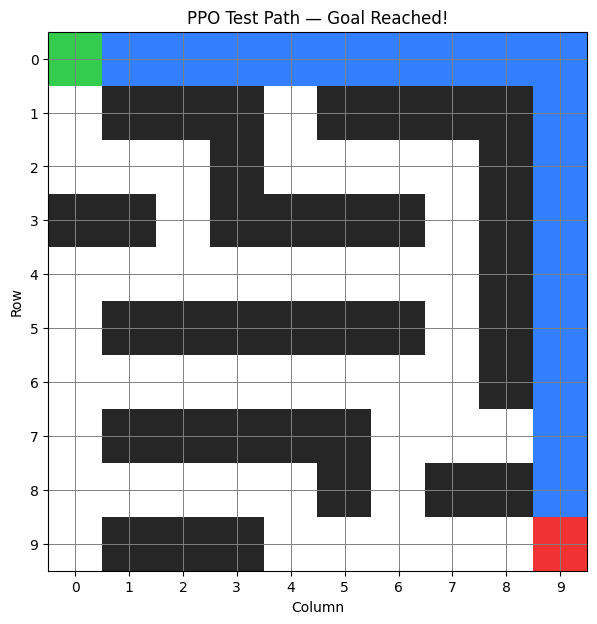

In [ ]:
obs, _ = env.reset(seed=SEED)
ppo_path = [START]
ppo_total_reward = 0
ppo_success = False

for _ in range(env.max_steps):
    action, _ = model.predict(obs, deterministic=True)

    obs, reward, terminated, truncated, _ = env.step(
        int(action)
    )

    ppo_total_reward += reward
    state = (
        obs // env.cols,
        obs % env.cols
    )

    if state != ppo_path[-1]:
        ppo_path.append(state)

    if terminated:
        ppo_success = True
        break

    if truncated:
        break

print("PPO Test Results")
print("Reached goal:", ppo_success)
print("Path length:", len(ppo_path) - 1)
print("Total reward:", ppo_total_reward)
print("Path:", ppo_path)

# Visualize the path
image = np.ones((*GRID.shape, 3))
image[GRID == 1] = [0.15, 0.15, 0.15]

for r, c in ppo_path:
    image[r, c] = [0.2, 0.5, 1.0]

image[START] = [0.2, 0.8, 0.3]
image[GOAL] = [0.95, 0.2, 0.2]

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.xticks(range(GRID.shape[1]))
plt.yticks(range(GRID.shape[0]))
plt.grid(True, color="gray", linewidth=0.7)
plt.title(f"PPO Test Path — {'Goal Reached!' if ppo_success else 'Goal Not Reached'}")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()

In [ ]:
import random
import time
from collections import deque

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

env = GridWorldEnv()

STATE_DIM = GRID.size
ACTION_DIM = env.action_space.n

print("Device:", device)
print("States:", STATE_DIM)
print("Actions:", ACTION_DIM)

Device: cpu
States: 100
Actions: 4


In [ ]:
def encode_state(state):
    one_hot = np.zeros(STATE_DIM, dtype=np.float32)
    one_hot[int(state)] = 1.0
    return one_hot


class Actor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, ACTION_DIM)
        )

    def forward(self, state):
        return torch.softmax(self.net(state), dim=-1)


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, ACTION_DIM)
        )

    def forward(self, state):
        return self.net(state)


actor = Actor().to(device)
critic1 = Critic().to(device)
critic2 = Critic().to(device)

target1 = Critic().to(device)
target2 = Critic().to(device)

target1.load_state_dict(critic1.state_dict())
target2.load_state_dict(critic2.state_dict())

actor_optimizer = optim.Adam(actor.parameters(), lr=3e-4)
critic1_optimizer = optim.Adam(critic1.parameters(), lr=3e-4)
critic2_optimizer = optim.Adam(critic2.parameters(), lr=3e-4)

print("SAC networks created!")

SAC networks created!


In [ ]:
replay_buffer = deque(maxlen=50000)

GAMMA = 0.99
ALPHA = 0.2          # Entropy coefficient
BATCH_SIZE = 128
WARMUP_STEPS = 1000
TOTAL_STEPS = 50000
TAU = 0.005

print("Replay buffer and hyperparameters ready!")

Replay buffer and hyperparameters ready!


In [ ]:
def soft_update(target, source):
    with torch.no_grad():
        for target_param, source_param in zip(
            target.parameters(), source.parameters()
        ):
            target_param.data.mul_(1 - TAU)
            target_param.data.add_(TAU * source_param.data)


def choose_action(state, deterministic=False):
    state_tensor = torch.tensor(
        encode_state(state), dtype=torch.float32, device=device
    ).unsqueeze(0)

    with torch.no_grad():
        probabilities = actor(state_tensor).squeeze(0)

    if deterministic:
        return int(torch.argmax(probabilities).item())

    return int(torch.multinomial(probabilities, 1).item())


episode_rewards_sac = []
episode_success_sac = []
recent_rewards = []

state, _ = env.reset(seed=SEED)
episode_reward = 0
episode_success = False
episode_steps = 0

start_time = time.perf_counter()

for step in range(TOTAL_STEPS):

    # Random exploration at the beginning
    if step < WARMUP_STEPS:
        action = env.action_space.sample()
    else:
        action = choose_action(state)

    next_state, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated

    replay_buffer.append((
        state, action, reward, next_state, float(terminated)
    ))

    episode_reward += reward
    episode_steps += 1

    if terminated:
        episode_success = True

    # Update networks once enough experience is available
    if len(replay_buffer) >= BATCH_SIZE and step >= WARMUP_STEPS:

        batch = random.sample(replay_buffer, BATCH_SIZE)

        states, actions, rewards, next_states, terminals = zip(*batch)

        states_t = torch.tensor(
            np.array([encode_state(s) for s in states]),
            dtype=torch.float32, device=device
        )
        next_states_t = torch.tensor(
            np.array([encode_state(s) for s in next_states]),
            dtype=torch.float32, device=device
        )
        actions_t = torch.tensor(
            actions, dtype=torch.long, device=device
        ).unsqueeze(1)
        rewards_t = torch.tensor(
            rewards, dtype=torch.float32, device=device
        ).unsqueeze(1)
        terminals_t = torch.tensor(
            terminals, dtype=torch.float32, device=device
        ).unsqueeze(1)

        # Critic target: entropy-regularized future value
        with torch.no_grad():
            next_probs = actor(next_states_t)
            next_log_probs = torch.log(next_probs + 1e-8)

            next_q = torch.minimum(
                target1(next_states_t),
                target2(next_states_t)
            )

            next_value = (
                next_probs * (next_q - ALPHA * next_log_probs)
            ).sum(dim=1, keepdim=True)

            target_q = (
                rewards_t
                + GAMMA * (1 - terminals_t) * next_value
            )

        current_q1 = critic1(states_t).gather(1, actions_t)
        current_q2 = critic2(states_t).gather(1, actions_t)

        loss1 = nn.functional.mse_loss(current_q1, target_q)
        loss2 = nn.functional.mse_loss(current_q2, target_q)

        critic1_optimizer.zero_grad()
        loss1.backward()
        critic1_optimizer.step()

        critic2_optimizer.zero_grad()
        loss2.backward()
        critic2_optimizer.step()

        # Actor update
        probs = actor(states_t)
        log_probs = torch.log(probs + 1e-8)

        with torch.no_grad():
            q_values = torch.minimum(
                critic1(states_t), critic2(states_t)
            )

        actor_loss = (
            probs * (ALPHA * log_probs - q_values)
        ).sum(dim=1).mean()

        actor_optimizer.zero_grad()
        actor_loss.backward()
        actor_optimizer.step()

        soft_update(target1, critic1)
        soft_update(target2, critic2)

    state = next_state

    if done:
        episode_rewards_sac.append(episode_reward)
        episode_success_sac.append(int(episode_success))

        state, _ = env.reset()
        episode_reward = 0
        episode_success = False
        episode_steps = 0

    if (step + 1) % 10000 == 0:
        recent = episode_success_sac[-50:]
        success_rate = 100 * np.mean(recent) if recent else 0
        print(
            f"Steps: {step + 1}/{TOTAL_STEPS} | "
            f"Recent success rate: {success_rate:.1f}%"
        )

sac_training_time = time.perf_counter() - start_time

print("\nSAC Training Complete")
print(f"Training time: {sac_training_time:.2f} seconds")
print(f"Completed episodes: {len(episode_rewards_sac)}")

Steps: 10000/50000 | Recent success rate: 100.0%
Steps: 20000/50000 | Recent success rate: 100.0%
Steps: 30000/50000 | Recent success rate: 100.0%
Steps: 40000/50000 | Recent success rate: 100.0%
Steps: 50000/50000 | Recent success rate: 100.0%

SAC Training Complete
Training time: 545.57 seconds
Completed episodes: 2713


SAC Test Results
Reached goal: True
Path length: 18
Total reward: 91.5
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]


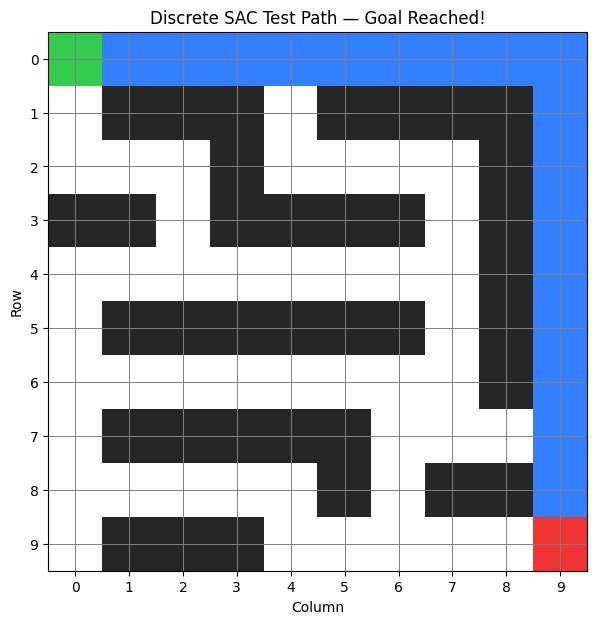

In [ ]:
state, _ = env.reset(seed=SEED)
sac_path = [START]
sac_total_reward = 0
sac_success = False

for _ in range(env.max_steps):
    action = choose_action(state, deterministic=True)

    next_state, reward, terminated, truncated, _ = env.step(action)
    sac_total_reward += reward

    next_position = (
        next_state // env.cols,
        next_state % env.cols
    )

    if next_position != sac_path[-1]:
        sac_path.append(next_position)

    state = next_state

    if terminated:
        sac_success = True
        break

    if truncated:
        break

print("SAC Test Results")
print("Reached goal:", sac_success)
print("Path length:", len(sac_path) - 1)
print("Total reward:", sac_total_reward)
print("Path:", sac_path)

image = np.ones((*GRID.shape, 3))
image[GRID == 1] = [0.15, 0.15, 0.15]

for r, c in sac_path:
    image[r, c] = [0.2, 0.5, 1.0]

image[START] = [0.2, 0.8, 0.3]
image[GOAL] = [0.95, 0.2, 0.2]

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.xticks(range(GRID.shape[1]))
plt.yticks(range(GRID.shape[0]))
plt.grid(True, color="gray", linewidth=0.7)
plt.title(
    f"Discrete SAC Test Path — "
    f"{'Goal Reached!' if sac_success else 'Goal Not Reached'}"
)
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()

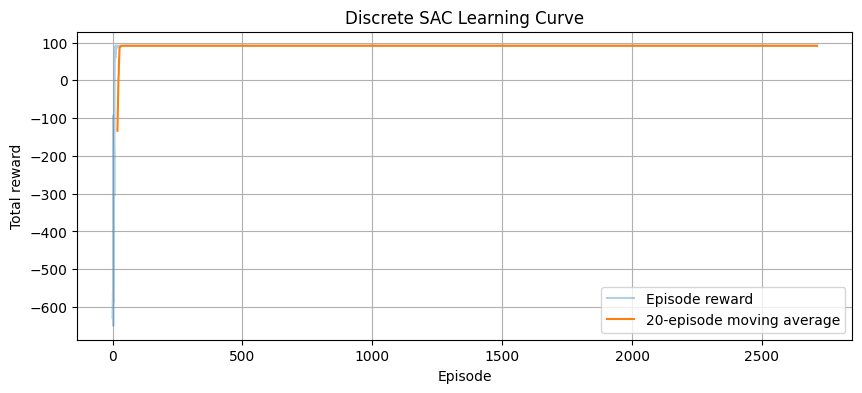

In [ ]:
if episode_rewards_sac:
    window = min(20, len(episode_rewards_sac))
    moving_avg = np.convolve(
        episode_rewards_sac,
        np.ones(window) / window,
        mode="valid"
    )

    plt.figure(figsize=(10, 4))
    plt.plot(episode_rewards_sac, alpha=0.35, label="Episode reward")
    plt.plot(
        range(window - 1, len(episode_rewards_sac)),
        moving_avg,
        label=f"{window}-episode moving average"
    )
    plt.title("Discrete SAC Learning Curve")
    plt.xlabel("Episode")
    plt.ylabel("Total reward")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No complete episodes recorded; inspect training settings.")